In [15]:
# 得到SEIR仓室模型各个状态的均值
def get_compartment_state_mean(rho_X_means_df, sort_X_results, timeStep):
    # 创建一个空列表来存储每个日期的rho_S均值
    rho_S_means = []
    rho_E_means = []
    rho_I_means = []
    rho_R_means = []
    Πi_means = []
    Pi_means = []

    # 对每一个时间步 求patches各个状态密度均值
    for date in range(timeStep+1):
        # 提取date为当前日期的所有行
        rows_X_date = sort_X_results[sort_X_results['date'] == date]
        # 计算rho_S列的均值
        rho_S_mean = rows_X_date['rho_S'].mean()
        rho_E_mean = rows_X_date['rho_E'].mean()
        rho_I_mean = rows_X_date['rho_I'].mean()
        rho_R_mean = rows_X_date['rho_R'].mean()
        Πi_mean = rows_X_date['Πi'].mean()
        Pi_mean = rows_X_date['Pi'].mean()
        # 将rho_S均值添加到列表中
        rho_S_means.append(rho_S_mean)
        rho_E_means.append(rho_E_mean)
        rho_I_means.append(rho_I_mean)
        rho_R_means.append(rho_R_mean)
        Πi_means.append(Πi_mean)
        Pi_means.append(Pi_mean)

    # 将列表添加到DataFrame中
    rho_X_means_df['rho_S Mean'] = rho_S_means
    rho_X_means_df['rho_E Mean'] = rho_E_means
    rho_X_means_df['rho_I Mean'] = rho_I_means
    rho_X_means_df['rho_R Mean'] = rho_R_means
    rho_X_means_df['Πi Mean'] = Πi_means
    rho_X_means_df['Pi Mean'] = Pi_means
    # 添加日期列
    rho_X_means_df['Date'] = range(timeStep+1)


    return rho_X_means_df


In [16]:
import pandas as pd
import numpy as np
from mmca import mmcaMeta_adjust

# 有向图权重
W = [[0.8, 0.6, 0.4], [0.5, 0.7, 0.1], [0.25, 0.3, 0.8]]

# 移动概率
p = 0.6
# 疾病传播参数
epi_params={'Lambda':0.03, 'beta':0.2, 'mu':0.4}

# 各社区人口数量
n_vec = [100, 150, 200]

# 社区数量
N = 3
patch_ids = list(range(N))

model_Meta = mmcaMeta_adjust(W=W, p=p, epi_params=epi_params, n_vec=n_vec, patch_ids=patch_ids)

E_0 = np.random.randint(1, 5, size = N)  # 初始预感染种子
I_0 = np.random.randint(1, 3, size = N)   # 初始感染种子

startTime = 0  # 开始日期
timeStep = 30 # 循环时间步

# 设置了每个舱室中存在的初始比例，以便启动马尔可夫过程
model_Meta.set_seed(E_0, I_0, startTime)

# 启动了MMCA模型，在该模型中，每天根据马尔可夫过程更新感染概率，设置时间步timestep
model_Meta.run_epidemic_spreading(timeStep)

simulation_results = model_Meta.out_df
sort_simulation_results = simulation_results.sort_values(by=['patch_id', 'date'])

# 组合文件名
file_name = f"sorted_results.csv"

# 将 DataFrame 写入 CSV 文件
sort_simulation_results.to_csv(file_name, index=True, encoding='gbk')




In [17]:
# 创建一个空的DataFrame来存储结果
columns1 = ['Date', 'rho_S Mean', 'rho_E Mean','rho_I Mean','rho_R Mean','Πi Mean','Pi Mean']
rho_means_df = pd.DataFrame(columns=columns1)

# 得到仓室模型各个状态的平均密度
graph = get_compartment_state_mean(rho_means_df, sort_simulation_results, timeStep)


In [18]:
graph

,Date,rho_S Mean,rho_E Mean,rho_I Mean,rho_R Mean,Πi Mean,Pi Mean
0,0,0.966667,0.022778,0.010556,0.000000,0.039342,0.039190
1,1,0.928702,0.056187,0.010889,0.004222,0.041192,0.041119
2,2,0.890513,0.083138,0.017771,0.008578,0.070393,0.070376
3,3,0.827854,0.129170,0.027290,0.015686,0.109355,0.109416
4,4,0.737290,0.193900,0.042208,0.026602,0.167594,0.167821
5,5,0.613615,0.278795,0.064105,0.043485,0.246592,0.247073
6,6,0.462179,0.374472,0.094222,0.069127,0.343259,0.344051
7,7,0.303544,0.458212,0.131427,0.106816,0.445508,0.446581
8,8,0.168574,0.501539,0.170499,0.159387,0.535334,0.536571
9,9,0.078749,0.491057,0.202607,0.227587,0.597683,0.598952


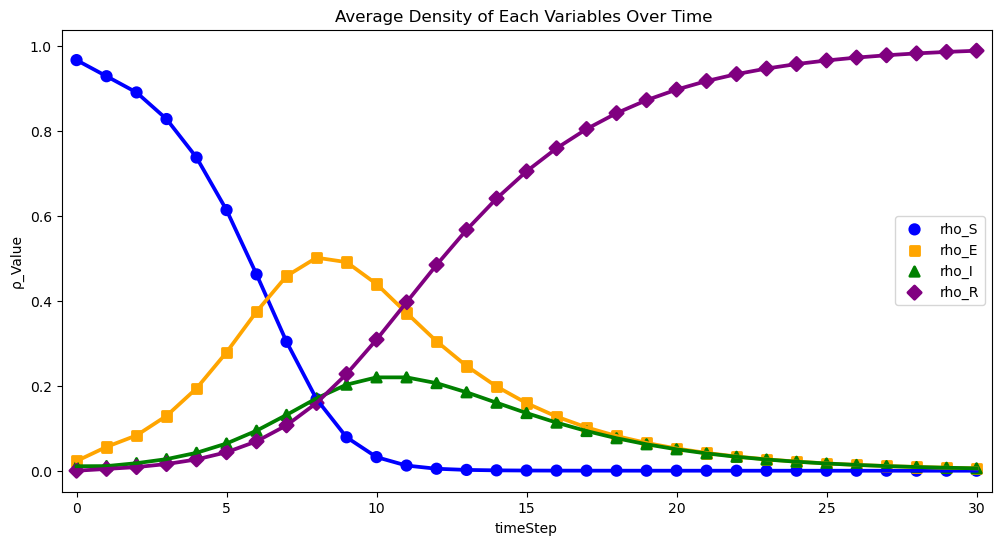

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 忽略FutureWarning
warnings.filterwarnings("ignore", category=FutureWarning)

 # 使用 sns.lineplot 绘制曲线
plt.figure(figsize=(12, 6))
sns.pointplot(data=graph, x='Date', y='rho_S Mean', label='rho_S', markers='o', color='blue')
sns.pointplot(data=graph, x='Date', y='rho_E Mean', label='rho_E', markers='s', color='orange')
sns.pointplot(data=graph, x='Date', y='rho_I Mean', label='rho_I', markers='^',color='green')
sns.pointplot(data=graph, x='Date', y='rho_R Mean', label='rho_R',markers='D', color='purple')

# 添加标题和标签
plt.title(f'Average Density of Each Variables Over Time ')
plt.xlabel("timeStep")
plt.ylabel("ρ_Value")
# 显示图例
plt.legend()

# 设置 x 轴刻度范围和间隔
plt.xticks(np.arange(0, timeStep + 1, 5))
# 显示图形
plt.show()